# Hiberno-English extraction pipeline

This notebook runs the extraction pipeline end to end, stage by stage.
Each stage names what it does and which library function does it.

Run top to bottom. Every stage that reads a file only reads from
`inputs/` (real inputs you supply locally -- see `inputs/README.md`) or
`data/<stage>/` (this notebook's own previous output).

**Status:** stages are added here one at a time as the repository is
built -- this is not yet the complete pipeline.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
INPUTS = REPO_ROOT / "inputs"
DATA = REPO_ROOT / "data"
sys.path.insert(0, str(SRC))

for d in ("01_ingest", "02_apparatus", "03_segmentation", "04_features", "05_e390",
          "06_retrieval", "07_h", "08_rule_based"):
    (DATA / d).mkdir(parents=True, exist_ok=True)

print("REPO_ROOT:", REPO_ROOT)
print("inputs/ present:", INPUTS.exists())

## Stage 0 -- Source document

The whole extraction pipeline operates on one witness document. It is
copyrighted and not shipped in this repository; place your own copy at
`inputs/source_witness.docx` (see `inputs/README.md`).

In [2]:
SOURCE_DOCX = INPUTS / "source_witness.docx"
if not SOURCE_DOCX.exists():
    raise FileNotFoundError(
        f"{SOURCE_DOCX} not found -- see inputs/README.md and place your "
        "own copy of the source document there before continuing.")

print("Found:", SOURCE_DOCX)

Found: d:\Experiments\Hiberno_english_Dictonary\Hiberno_english_Dictonary_Springer\public_release\hiberno-english-grounded-reader\inputs\source_witness.docx


## Stage 1 -- OOXML ingest

Reads the `.docx` as a raw zip/XML package and emits one row per
text-bearing run, in document order, with the *effective* character
formatting resolved through Word's real inheritance chain (document
defaults -> paragraph style -> character style -> direct formatting).
Several of those properties (italic, bold, caps, small caps, strike)
are toggles under the OOXML spec: where two levels of the hierarchy
each set one, the effective value is their XOR, not just the nearest
one -- this project's source relies on exactly that behaviour in
places, so resolving it correctly (not approximately) matters.

Before returning, it independently recounts every text node and
character in the raw XML and checks the emitted rows match exactly;
a mismatch raises `ConservationError` rather than returning a partial
result. This is the only stage that reads the raw document XML --
everything downstream works from this run table.

Function: `hiberno_english.ingest.ingest_docx`.
Output: `data/01_ingest/runs.parquet` (gitignored -- see `inputs/README.md`;
its `text` column reconstructs the document body verbatim).

In [3]:
from hiberno_english.ingest import ingest_docx, write_runs_parquet

ingest_result = ingest_docx(SOURCE_DOCX)
report = ingest_result.conservation

print("conservation_pass:", report.conservation_pass)
print("expected_text_nodes / emitted_rows:", report.expected_text_nodes, "/", report.emitted_rows)
print("expected_chars / emitted_chars:", report.expected_chars, "/", report.emitted_chars)
print("character_styles_defined:", report.character_styles_defined)
assert report.conservation_pass, "conservation gate failed -- see report above"

runs = ingest_result.runs
write_runs_parquet(runs, DATA / "01_ingest" / "runs.parquet")
print("runs table:", runs.num_rows, "rows ->", DATA / "01_ingest" / "runs.parquet")

conservation_pass: True
expected_text_nodes / emitted_rows: 24641 / 24641
expected_chars / emitted_chars: 917946 / 917946
character_styles_defined: 10
runs table: 24641 rows -> d:\Experiments\Hiberno_english_Dictonary\Hiberno_english_Dictonary_Springer\public_release\hiberno-english-grounded-reader\data\01_ingest\runs.parquet


## Stage 2 -- Apparatus / authority extraction

Parses the source's own front and back matter -- abbreviations,
pronunciation scheme, literary and non-literary source keys,
bibliography -- into eleven closed authority tables that constrain
extraction downstream. These are the source's own declared
conventions, not inferred ones: a closed vocabulary classifies every
abbreviation, and anything outside it is reported, never guessed into
the nearest bucket.

The bibliography/literary-sources parsing is the hard part: entries
wrap across paragraphs with no structural signal, a paragraph can hold
more than one entry, and an article's roman quoted title has to be
told apart from its italic container journal. Where a work has no
year, the parser records *why* -- the source declares it unknown, a
misprint, a chapter whose date lives at its collection's own entry, or
genuinely unresolved -- rather than leaving every case indistinguishable.

Zero unexplained residue and zero unclassified abbreviations are
required: the function raises rather than returning a partial result.

Function: `hiberno_english.apparatus.extract_authorities`.
Output: `data/02_apparatus/*.parquet` (eleven tables -- structural/
numeric, no dictionary prose beyond short labels, tracked normally).

In [4]:
from hiberno_english.apparatus import extract_authorities, write_authority_tables

apparatus_result = extract_authorities(runs)
write_authority_tables(apparatus_result.tables, DATA / "02_apparatus")

print("apparatus tables (rows):")
for name, n in sorted(apparatus_result.report.table_rows.items()):
    print(f"  {name:<22} {n}")
print("residue_total:", apparatus_result.report.residue_total)
print("unclassified_abbreviations:", apparatus_result.report.unclassified_abbreviations)

apparatus tables (rows):
  bibliography           248
  citation_convention    3
  editorial_abbrevs      2
  ipa_inventory          46
  language_codes         24
  literary_sources       124
  non_literary_sources   141
  pos_labels             17
  reference_sigla        3
  register_labels        6
  symbols                2
residue_total: 0
unclassified_abbreviations: []


## Stage 3 -- Dictionary segmentation

Locates where one entry ends and the next begins, classifies what
kind each is, and assigns durable IDs -- purely from typographic
structure. A letter-section heading is a paragraph at a specific type
size whose whole text is a single letter A-Z. A cross-reference
(redirect) entry is marked specifically by an italic "see" run right
after the headword -- not just the larger of the source's two
headword typefaces, since that typeface is also used on some ordinary
full entries. The homonym index (disambiguating identically-spelled
headwords) is captured here too: a lone digit run directly abutting
the headword, but only before any pronunciation slash opens -- the
same digit styling is separately used for an inline homonym citation
elsewhere inside a definition, and that position check is what tells
the two apart.

The gate re-walks the raw document XML completely independently of
the run table this stage itself consumes, and checks that the emitted
entry count, character count, and entry IDs reconcile, and that
concatenating every entry's text reconstructs the source body exactly
with zero orphan text.

Function: `hiberno_english.segmentation.segment_dictionary` (needs the
source path again, for that independent reconciliation).
Output: `data/03_segmentation/entries.parquet` (gitignored -- its `raw`
column is every entry's text verbatim).

In [5]:
import pyarrow.parquet as pq
from hiberno_english.segmentation import segment_dictionary

segmentation_result = segment_dictionary(runs, SOURCE_DOCX)
seg_report = segmentation_result.report

print("entry_counts:", seg_report.entry_counts)
print("homonym_marked:", seg_report.homonym_marked)
print("duplicate_entry_ids:", seg_report.duplicate_entry_ids)
print("entry_count_reconciles (independent re-walk of the raw XML):", seg_report.entry_count_reconciles)
print("zone_conserves_no_orphan_text:", seg_report.zone_conserves_no_orphan_text)

assert not seg_report.duplicate_entry_ids, "duplicate entry_id(s) -- durable-ID gate failed"
assert seg_report.entry_count_reconciles, "independent entry/char-count reconciliation failed"
assert seg_report.zone_conserves_no_orphan_text, "orphan text outside any emitted entry/letter-header"

entries = segmentation_result.entries
pq.write_table(entries, DATA / "03_segmentation" / "entries.parquet")
print("entries table:", entries.num_rows, "rows ->", DATA / "03_segmentation" / "entries.parquet")

n_lexical = sum(1 for t in entries.column("entry_type").to_pylist() if t != "letter_header")
print("lexical entries (entry_type != letter_header):", n_lexical)

entry_counts: {'full': 3868, 'cross_ref': 31, 'letter_header': 25, 'total': 3924}
homonym_marked: 182
duplicate_entry_ids: []
entry_count_reconciles (independent re-walk of the raw XML): True
zone_conserves_no_orphan_text: True
entries table: 3924 rows -> d:\Experiments\Hiberno_english_Dictonary\Hiberno_english_Dictonary_Springer\public_release\hiberno-english-grounded-reader\data\03_segmentation\entries.parquet
lexical entries (entry_type != letter_header): 3899


## Data sampling

Two stages exist purely to support how the 390-entry development
sample (E390) is drawn and how structural precedent is retrieved --
neither is part of extraction itself. The structural feature map phi
(below) is computed first; the stratified sample design that
consumes it follows as its own stage.

### Stage 4 -- Structural feature map phi

Builds one feature vector per lexical entry, computed purely from
source typography and raw text -- never from any reader's output or
adjudicated value. This has to be computable before any reader runs,
so it can be used to design the stratified sample without leaking
anything about extraction quality into the sample design itself.

The features are mostly counts -- pronunciation spans, etymology
markers, numbered senses, quote pairs, region codes, italic/small-caps/
all-caps run counts, Irish-character counts, "also"/"cf."/"see"
occurrences -- source-side proxies for how much of the extraction
schema an entry is likely to exercise, not a judgement of correctness.
`entry_id`/`letter_section`/`homonym_index`/`para_idx` are carried
through as join metadata only, excluded from the feature set itself so
they can never leak into clustering or similarity downstream.

Raises rather than silently zero-filling if any lexical entry has a
duplicate ID, a missing or shared `para_idx`, or no matching run
evidence at all.

Function: `hiberno_english.features.build_structural_features`.
Output: `data/04_features/phi.parquet` (numeric/structural, tracked
normally).

In [6]:
from hiberno_english.features import build_structural_features, FEATURE_COLUMNS

phi = build_structural_features(entries, runs)
pq.write_table(phi, DATA / "04_features" / "phi.parquet")
print("phi table:", phi.num_rows, "rows,", len(phi.schema.names), "columns ->",
     DATA / "04_features" / "phi.parquet")
print("FEATURE_COLUMNS (phi):", len(FEATURE_COLUMNS))

phi table: 3899 rows, 35 columns -> d:\Experiments\Hiberno_english_Dictonary\Hiberno_english_Dictonary_Springer\public_release\hiberno-english-grounded-reader\data\04_features\phi.parquet
FEATURE_COLUMNS (phi): 31


### What phi actually measures

31 features per entry: 28 counts (pronunciation spans, etymology
markers, numbered senses, quote pairs, region codes, run-styling
counts, punctuation, capitalised words, Irish characters, and a
handful of lexical markers like "also"/"cf."/"see") plus 3 booleans
(`is_cross_ref`, `has_homonym`, `is_pointer`).

The chart below shows, for every feature, what share of the 3,899
entries have it present at all (count > 0, or True) -- not its
magnitude. Two features are flat zero across the whole corpus:
`n_smallcaps_run` and `n_allcaps_run`. That's a real, reported finding,
not a bug being hidden -- the source's own citation-convention table
(Stage 2) states small capitals mark cross-references, but no run in
this witness document's main body actually carries the `smallCaps`
toggle; that convention's effective rendering must rely on something
else entirely (`n_xref_run`, keyed on the `1Text` character style,
does fire for 1,332 entries -- it is almost certainly what the
convention actually surfaces as in this document).

In [7]:
import matplotlib.pyplot as plt

# Shared chart style for every plot in this notebook: a categorical
# palette validated for colorblind-safe adjacent-pair separation, plus a
# consistent light, low-ink chrome (hairline gridlines, no heavy spines).
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
RED, MIDGRAY = "#e34948", "#c3c2b7"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10,
    "text.color": INK,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "legend.frameon": False,
})

zero-coverage features: ['n_smallcaps_run', 'n_allcaps_run']


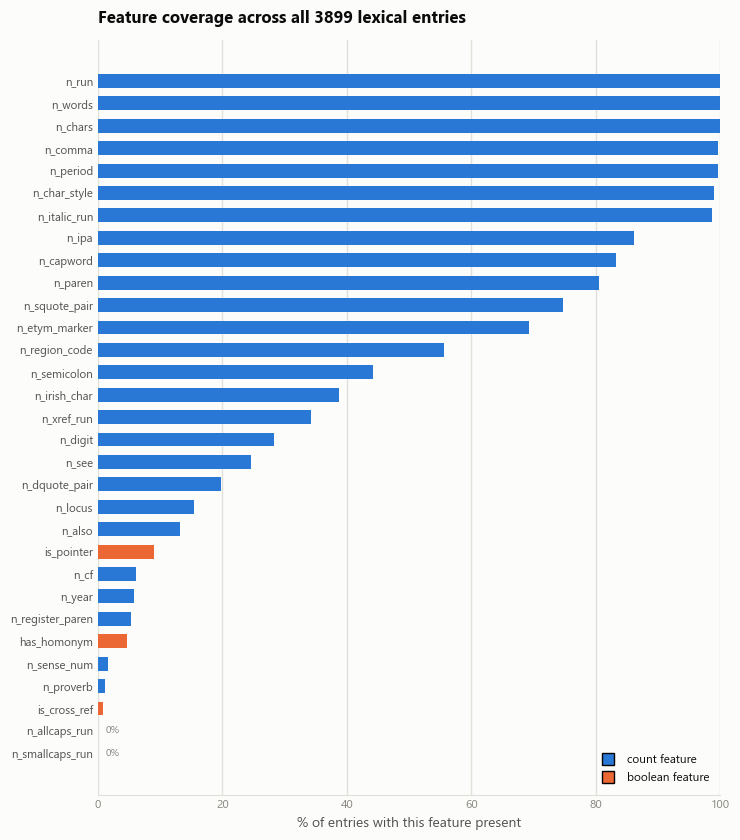

In [8]:
from hiberno_english.features import COUNT_FEATURES, BOOL_FEATURES

df = phi.to_pandas()
n = len(df)
coverage = {f: (df[f] > 0).sum() / n * 100 for f in COUNT_FEATURES}
coverage.update({f: df[f].sum() / n * 100 for f in BOOL_FEATURES})
print("zero-coverage features:", [k for k, v in coverage.items() if v == 0])

items = sorted(coverage.items(), key=lambda kv: kv[1])
names = [k for k, _ in items]
vals = [v for _, v in items]
colors = [ORANGE if k in BOOL_FEATURES else BLUE for k in names]

fig, ax = plt.subplots(figsize=(7.5, 8.5))
bars = ax.barh(names, vals, color=colors, height=0.62, zorder=3)
ax.set_xlim(0, 100)
ax.set_xlabel("% of entries with this feature present")
ax.set_title(f"Feature coverage across all {n} lexical entries", fontsize=12, fontweight="bold", loc="left", pad=12)
ax.xaxis.grid(True, color=GRID, linewidth=1, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(axis="y", length=0, labelsize=8.3, labelcolor=INK_SECONDARY)
ax.tick_params(axis="x", length=0, labelsize=8.5)
for b, v in zip(bars, vals):
    if v == 0:
        ax.text(1.2, b.get_y() + b.get_height() / 2, "0%", va="center", ha="left",
                 fontsize=7.5, color=INK_MUTED)
legend_handles = [
    plt.Line2D([0], [0], marker="s", color="none", markerfacecolor=BLUE, markersize=9, label="count feature"),
    plt.Line2D([0], [0], marker="s", color="none", markerfacecolor=ORANGE, markersize=9, label="boolean feature"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=8.5, handletextpad=0.6)
plt.tight_layout()
plt.show()

### Stage 5 -- E390 stratified sample + frozen transform T

Draws the 390-entry development sample. Every entry is checked against
three conditions in a fixed precedence -- does the source itself number
more than one sense? does it carry a homonym index? is it a pointer or
cross-reference? -- and the first match sends it to a protected hard
stratum; homonym entries are grouped by family (never split) before
anything else happens. Everything left over -- the "bulk" -- is
projected through a fixed transform (log1p -> StandardScaler -> PCA,
25 of phi's 28 count features, retaining enough components for 90%
variance) and clustered with a Gaussian mixture, picking the largest
number of clusters whose smallest one still holds at least 100 entries.

Of the 390-entry budget, the multi-sense stratum is taken in full
(protected, not negotiable), the pointer stratum is capped at 20
(structurally trivial, more wouldn't add signal), and the rest is
split across the homonym stratum and each cluster in proportion to
population size *and* how much historical readers actually disagreed
on that stratum's entries -- bigger, more contentious strata get
proportionally more of the budget. One seeded random draw, consumed in
a fixed stratum order, does the actual selection.

Function: `hiberno_english.sampling.design_e390`. Needs the frozen,
externally supplied disagreement scores at
`inputs/sample_disagreement.parquet` (see `inputs/README.md`).
Output: `data/05_e390/design_table.parquet`, `selected_entry_ids.json`,
`structural_transform.json` -- entry IDs, stratum labels and counts
only, no dictionary prose, tracked normally.

In [9]:
import json

(DATA / "05_e390").mkdir(parents=True, exist_ok=True)

from hiberno_english.sampling import design_e390

disagreement_path = INPUTS / "sample_disagreement.parquet"
if not disagreement_path.exists():
    raise FileNotFoundError(
        f"{disagreement_path} not found -- see inputs/README.md.")
disagreement = pq.read_table(disagreement_path)

e390 = design_e390(phi, disagreement)
r = e390.report

print("E390 selected size:", len(e390.selected_entry_ids))
print("seed:", r.seed, " budget:", r.budget, " frame_size:", r.frame_size, " bulk_size:", r.bulk_size)
print("GMM clusters selected (k):", r.selected_k, " | retained PCA components:", r.retained_pca_components,
      " | explained variance:", round(r.explained_variance, 4))
print()
print("population by stratum:", dict(sorted(r.population_by_stratum.items())))
print("realised allocation:  ", dict(sorted(r.realised_allocation.items())))

pq.write_table(e390.design_table, DATA / "05_e390" / "design_table.parquet")
(DATA / "05_e390" / "selected_entry_ids.json").write_text(
    json.dumps(list(e390.selected_entry_ids), indent=2), encoding="utf-8")
(DATA / "05_e390" / "structural_transform.json").write_text(
    json.dumps(e390.transform.to_dict(), indent=2), encoding="utf-8")
print()
print("wrote design_table.parquet, selected_entry_ids.json, structural_transform.json")

E390 selected size: 390
seed: 20260821  budget: 390  frame_size: 3899  bulk_size: 3316
GMM clusters selected (k): 5  | retained PCA components: 14  | explained variance: 0.9164

population by stratum: {'C0': 239, 'C1': 538, 'C2': 297, 'C3': 786, 'C4': 1456, 'H_homonym': 177, 'H_multisense': 63, 'H_pointer': 343}
realised allocation:   {'C0': 20, 'C1': 48, 'C2': 30, 'C3': 73, 'C4': 120, 'H_homonym': 16, 'H_multisense': 63, 'H_pointer': 20}

wrote design_table.parquet, selected_entry_ids.json, structural_transform.json


#### Figure 1 -- the population really is heterogeneous

The columns below are the real, final strata E390 actually used --
not an approximation -- each a standardised mean of `log1p(feature)`
against the whole population, so red means "above the population
average," blue means "below," for that stratum and feature. The
`Pointer` stratum is the clearest story: far below average on almost
every feature except cross-reference and "see" markers, because a
pointer entry's entire content *is* "X, see Y." The GMM clusters show
softer, more gradual differences -- exactly what clustering on
structural shape, rather than a hand-picked rule, should produce.

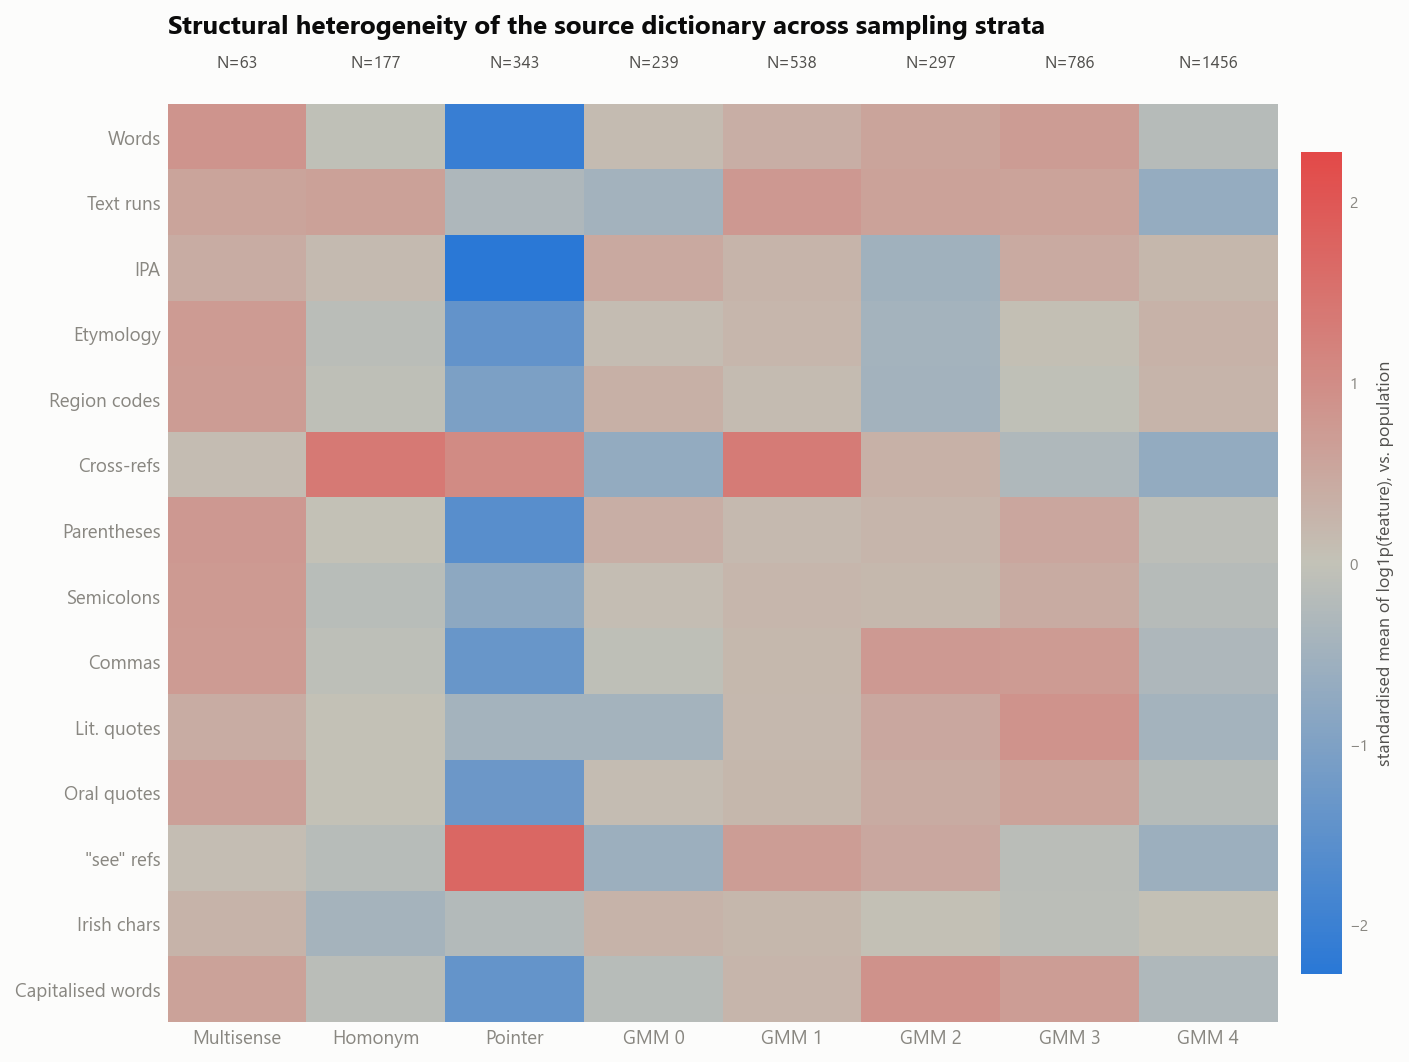

In [10]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

dtab = e390.design_table.to_pandas()
df = df.merge(dtab[["entry_id", "stratum"]], on="entry_id")

STRATA_ORDER = ["H_multisense", "H_homonym", "H_pointer", "C0", "C1", "C2", "C3", "C4"]
STRATA_LABELS = {"H_multisense": "Multisense", "H_homonym": "Homonym", "H_pointer": "Pointer",
                  "C0": "GMM 0", "C1": "GMM 1", "C2": "GMM 2", "C3": "GMM 3", "C4": "GMM 4"}

FEATURES = [
    ("n_words", "Words"), ("n_run", "Text runs"), ("n_ipa", "IPA"),
    ("n_etym_marker", "Etymology"), ("n_region_code", "Region codes"),
    ("n_xref_run", "Cross-refs"), ("n_paren", "Parentheses"),
    ("n_semicolon", "Semicolons"), ("n_comma", "Commas"),
    ("n_dquote_pair", "Lit. quotes"), ("n_squote_pair", "Oral quotes"),
    ("n_see", "\"see\" refs"), ("n_irish_char", "Irish chars"),
    ("n_capword", "Capitalised words"),
]

df_z = df.copy()
for col, _ in FEATURES:
    x = np.log1p(df[col].values.astype(float))
    df_z[col] = (x - x.mean()) / x.std()

matrix = np.zeros((len(FEATURES), len(STRATA_ORDER)))
for j, st in enumerate(STRATA_ORDER):
    sub = df_z[df_z.stratum == st]
    for i, (col, _) in enumerate(FEATURES):
        matrix[i, j] = sub[col].mean()

vmax = np.abs(matrix).max()
cmap = LinearSegmentedColormap.from_list("div", [BLUE, MIDGRAY, RED], N=256)

fig, ax = plt.subplots(figsize=(9.5, 7.2))
im = ax.imshow(matrix, cmap=cmap, vmin=-vmax, vmax=vmax, aspect="auto")

ax.set_xticks(range(len(STRATA_ORDER)))
ax.set_xticklabels([STRATA_LABELS[s] for s in STRATA_ORDER], fontsize=9)
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels([lbl for _, lbl in FEATURES], fontsize=9)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

for j, st in enumerate(STRATA_ORDER):
    ax.text(j, -1.0, f"N={r.population_by_stratum[st]}", ha="center", va="bottom",
            fontsize=8, color=INK_SECONDARY)

ax.set_title("Structural heterogeneity of the source dictionary across sampling strata",
             fontsize=12.5, fontweight="bold", loc="left", pad=34)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("standardised mean of log1p(feature), vs. population", fontsize=8.5, color=INK_SECONDARY)
cbar.ax.tick_params(length=0, labelsize=7.5)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

### Also drawing H390, the held-out comparison

H390 is a second 390-entry sample, disjoint from E390, drawn from
whatever's left (`D \ E390`) once E390 is removed. It reuses E390's own
frozen stratum and homonym-group assignments exactly -- it never
refits the transform, never reclusters, never recomputes disagreement
-- and it shares E390's own draw mechanics unchanged. What it can't
reuse is the allocation: by the time E390 is drawn, the multisense
stratum is 100% exhausted (E390 already took all 63 that exist), so
H390 has zero left to draw from there. Its allocation across the
remaining seven strata is therefore an explicit, externally-decided
redistribution of that exhausted share -- not something this function
computes -- recorded in a frozen manifest alongside the seed used.

Function: `hiberno_english.sampling.draw_h390`, given
`inputs/heldout_h_manifest.json`'s real `nominal_allocation`/`seed`
(no dictionary prose, safe to track). Output: `data/07_h/design_table.parquet`,
`selected_entry_ids.json`.

In [11]:
(DATA / "07_h").mkdir(parents=True, exist_ok=True)

from hiberno_english.sampling import draw_h390

manifest_path = INPUTS / "heldout_h_manifest.json"
if not manifest_path.exists():
    raise FileNotFoundError(f"{manifest_path} not found -- see inputs/README.md.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

h390 = draw_h390(
    e390.design_table,
    nominal_allocation=manifest["nominal_allocation"],
    seed=manifest["seed"],
    excluded_stratum=manifest["excluded_stratum"],
    excluded_stratum_reason=manifest["excluded_stratum_reason"],
)
rh = h390.report

print("H390 selected size:", len(h390.selected_entry_ids))
print("H390 membership sha256:", h390.ordered_membership_sha256())
print("matches frozen manifest hash:", h390.ordered_membership_sha256() == manifest["h_ordered_membership_sha256"])
print("frame_size (D minus E390):", rh.frame_size)
print("population by stratum:", dict(sorted(rh.population_by_stratum.items())))
print("realised allocation:  ", dict(sorted(rh.realised_allocation.items())))

pq.write_table(h390.design_table, DATA / "07_h" / "design_table.parquet")
(DATA / "07_h" / "selected_entry_ids.json").write_text(
    json.dumps(list(h390.selected_entry_ids), indent=2), encoding="utf-8")
print()
print("wrote design_table.parquet, selected_entry_ids.json")

H390 selected size: 390
H390 membership sha256: 67e9650a4a59247f5a823d1e8a299b2633771e1a15daf9c729c5646ff91613b3
matches frozen manifest hash: True
frame_size (D minus E390): 3509
population by stratum: {'C0': 219, 'C1': 490, 'C2': 267, 'C3': 713, 'C4': 1336, 'H_homonym': 161, 'H_pointer': 323}
realised allocation:   {'C0': 24, 'C1': 57, 'C2': 36, 'C3': 87, 'C4': 143, 'H_homonym': 20, 'H_pointer': 23}

wrote design_table.parquet, selected_entry_ids.json


#### Figure 2 -- what stratification bought, measured against chance

Each stratum gets a pair: E390 on the left (simulated against the full
3,899-entry population), H390 on the right (simulated against the
3,509 entries left once E390 is removed) -- 10,000 simple-random draws
each, giving the grey range; the diamond marks proportional allocation
(budget x population share, the SRS range's own centre); the dot is
the real, realised count. `Multisense` has no H390 side at all -- not
a zero, an absence, since E390 already took every multisense entry
that exists. For `Multisense`'s E390 side: simple random sampling
would land fewer than 10 entries (the minimum needed to even estimate
within-stratum variance) in **90.4% of simulated draws**, typically
around 6 -- E390 guarantees all 63. `Pointer` moves the other way for
both samples, deliberately capped below chance. The two samples
deviate from proportional allocation in the *same direction* on every
stratum they share, which is what reusing one frozen stratification
for two independent draws should look like. This doesn't claim either
sample is a better estimator of population-level accuracy -- only that
the design controls which structural configurations each development
set actually contains, rather than leaving that to chance.

P(E390 simple random sampling gives fewer than 10 Multisense entries): 90.4%


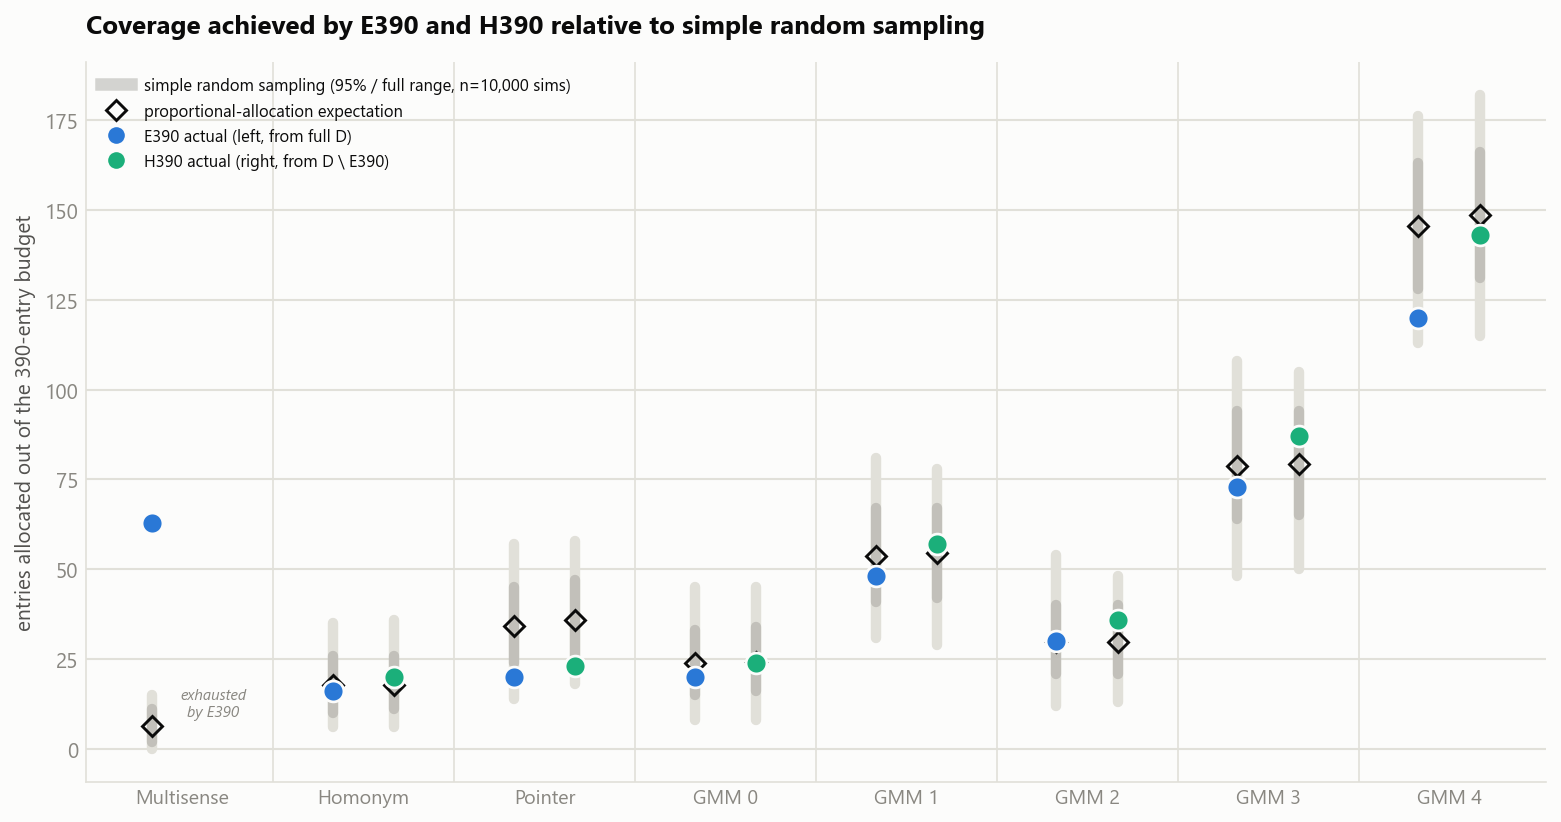

In [12]:
MIN_PER_STRATUM = 10  # same threshold design_e390 itself uses for Neyman allocation

dtab_e = e390.design_table.to_pandas()
ids_e = dtab_e["entry_id"].to_numpy()
strat_e = dtab_e["stratum"].to_numpy()
dtab_h = h390.design_table.to_pandas()
ids_h = dtab_h["entry_id"].to_numpy()
strat_h = dtab_h["stratum"].to_numpy()

rng_e = np.random.default_rng(12345)
rng_h = np.random.default_rng(67890)
n_sims = 10_000
idx_e, idx_h = np.arange(len(ids_e)), np.arange(len(ids_h))

counts_e = {s: np.zeros(n_sims, dtype=int) for s in STRATA_ORDER}
counts_h = {s: np.zeros(n_sims, dtype=int) for s in STRATA_ORDER if s != "H_multisense"}
for t in range(n_sims):
    draw_e = rng_e.choice(idx_e, size=r.budget, replace=False)
    ve, ce = np.unique(strat_e[draw_e], return_counts=True)
    map_e = dict(zip(ve, ce))
    for s in STRATA_ORDER:
        counts_e[s][t] = map_e.get(s, 0)
    draw_h = rng_h.choice(idx_h, size=rh.budget, replace=False)
    vh, ch = np.unique(strat_h[draw_h], return_counts=True)
    map_h = dict(zip(vh, ch))
    for s in counts_h:
        counts_h[s][t] = map_h.get(s, 0)

prop_e = {s: r.budget * r.population_by_stratum[s] / r.frame_size for s in STRATA_ORDER}
prop_h = {s: rh.budget * rh.population_by_stratum[s] / rh.frame_size for s in counts_h}
fail_e = float((counts_e["H_multisense"] < MIN_PER_STRATUM).mean())
print(f"P(E390 simple random sampling gives fewer than 10 Multisense entries): {fail_e:.1%}")

fig, ax = plt.subplots(figsize=(10.5, 5.6))
x = np.arange(len(STRATA_ORDER))
off = 0.17

for i, s in enumerate(STRATA_ORDER):
    xe = i - off
    lo2, hi2 = counts_e[s].min(), counts_e[s].max()
    lo, hi = np.percentile(counts_e[s], 2.5), np.percentile(counts_e[s], 97.5)
    ax.plot([xe, xe], [lo2, hi2], color=GRID, linewidth=5, solid_capstyle="round", zorder=1)
    ax.plot([xe, xe], [lo, hi], color=INK_MUTED, linewidth=5, alpha=0.35, solid_capstyle="round", zorder=2)
    ax.plot(xe, prop_e[s], marker="D", markersize=7, markerfacecolor="none",
            markeredgecolor=INK, markeredgewidth=1.4, linestyle="none", zorder=4)
    ax.plot(xe, r.realised_allocation[s], marker="o", markersize=10, color=BLUE, zorder=5,
            markeredgecolor=SURFACE, markeredgewidth=1.3)

    xh = i + off
    if s == "H_multisense":
        ax.text(xh, 8, "exhausted\nby E390", ha="center", va="bottom", fontsize=7.3,
                color=INK_MUTED, style="italic")
        continue
    lo2h, hi2h = counts_h[s].min(), counts_h[s].max()
    loh, hih = np.percentile(counts_h[s], 2.5), np.percentile(counts_h[s], 97.5)
    ax.plot([xh, xh], [lo2h, hi2h], color=GRID, linewidth=5, solid_capstyle="round", zorder=1)
    ax.plot([xh, xh], [loh, hih], color=INK_MUTED, linewidth=5, alpha=0.35, solid_capstyle="round", zorder=2)
    ax.plot(xh, prop_h[s], marker="D", markersize=7, markerfacecolor="none",
            markeredgecolor=INK, markeredgewidth=1.4, linestyle="none", zorder=4)
    ax.plot(xh, rh.realised_allocation[s], marker="o", markersize=10, color=AQUA, zorder=5,
            markeredgecolor=SURFACE, markeredgewidth=1.3)

for i in range(1, len(STRATA_ORDER)):
    ax.axvline(i - 0.5, color=GRID, linewidth=0.8, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels([STRATA_LABELS[s] for s in STRATA_ORDER], fontsize=9.5)
ax.set_ylabel("entries allocated out of the 390-entry budget")
ax.set_title("Coverage achieved by E390 and H390 relative to simple random sampling",
             fontsize=12.5, fontweight="bold", loc="left", pad=14)
ax.yaxis.grid(True, color=GRID, linewidth=1, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_color(GRID)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(length=0)

legend_handles = [
    plt.Line2D([0], [0], color=INK_MUTED, lw=6, alpha=0.35, label="simple random sampling (95% / full range, n=10,000 sims)"),
    plt.Line2D([0], [0], marker="D", color="none", markerfacecolor="none", markeredgecolor=INK,
               markersize=7, markeredgewidth=1.4, label="proportional-allocation expectation"),
    plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=BLUE, markeredgecolor=SURFACE,
               markersize=9, label="E390 actual (left, from full D)"),
    plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=AQUA, markeredgecolor=SURFACE,
               markersize=9, label="H390 actual (right, from D \\ E390)"),
]
ax.legend(handles=legend_handles, loc="upper left", fontsize=8, handlelength=1.8)
plt.tight_layout()
plt.show()

## Stage 6 -- Deterministic resolution (rho)

A pure annotation pass over an already-assembled `Entry` -- it never
calls a model and never retrieves anything. It fills in exactly two
kinds of metadata no reader can know on its own, because both need a
corpus-wide lookup built from source data the reader never sees:

- `Region.resolved_name`/`.source_type` -- grounding an informant code
  plus county (e.g. "JM, Cork") against the informant/bibliography
  authority tables from Stage 2.
- `CrossReference.resolution`/`.targets`/`.resolves` -- grounding a
  "see X" pointer against a corpus-wide headword index built from
  every entry's own raw text (Stage 3): strict match first, then a
  loose fallback (hyphens/apostrophes/spaces stripped), then a small,
  explicitly hand-verified alias table for genuinely irregular cases,
  each tagged with *why* (inflection, spelling, truncation, or a
  sub-entry).

It is reader-agnostic: the same function applies identically to a
rule-based or an LLM reader's raw output, and never guesses past what
the source actually disambiguates -- a headword shared by homonyms, or
an informant code shared by several people, comes back as every
candidate, or stays unresolved, never collapsed to one.

**Note on ordering:** the original experiment sequences this after
structural retrieval; this rebuild does resolution and the rule-based
reader first instead, since RB genuinely depends on resolution (RB =
rho(RB_raw)) while retrieval depends on neither. Stages from here on
are numbered by this repository's own build order, not the original
section order.

Functions: `hiberno_english.resolution.build_resolution_context`,
`resolve_entry`. Needs only Stage 2's authority tables and Stage 3's
segmented entries -- no new inputs.

In [13]:
from hiberno_english.resolution import build_resolution_context

resolution_context = build_resolution_context(entries, apparatus_result.tables)

print("strict headword index size:", len(resolution_context.strict_index))
print("loose headword index size:", len(resolution_context.loose_index))
print("homonym map size:", len(resolution_context.homonym_map))
print("informant rows indexed:", len(resolution_context.informant_rows))
print("bibliography keys indexed:", len(resolution_context.bibliography_by_key))

strict headword index size: 3874
loose headword index size: 3874
homonym map size: 182
informant rows indexed: 117
bibliography keys indexed: 360


## Stage 7 -- Rule-based reader (RB)

The deterministic baseline extraction -- no model, no retrieval, pure
pattern-matching against each paragraph's raw text and its typographic
run styling. Two structural signals carry most of the weight: a run in
the source's "0Text" character style marks a closed-vocabulary POS/
register label or an etymon; a run styled "1Text" marks a
cross-reference target. Everything else is closed-vocabulary matching
(Stage 2's authority tables) or plain punctuation/typography pattern
matching.

It runs as a sequential pipeline per entry -- headword, pronunciation,
variant forms; POS/register labels; etymology; senses, each with its
own regions, attestations, cross-references -- assembled into an
`Entry`. A pointer entry whose target lost its usual styling (a real,
documented source inconsistency) still gets a target recovered from
raw text, explicitly marked `SOURCE_ERROR` rather than silently
guessed. A grammatical-looking term outside the closed vocabulary is
logged as an `OBSERVED_EXTENSION` decision, never mapped onto the
nearest known term.

RB never resolves identity itself -- `RB = rho(RB_raw)`, with rho
(Stage 6) applied afterward, and a composition-boundary check that
raises if resolution ever touches a field it isn't allowed to.

Functions: `hiberno_english.readers.rule_based.build_rule_based_context`,
`read_rule_based_entry`. Output: `data/08_rule_based/rb.jsonl`
(gitignored -- a complete structured transcription of every entry, the
same sensitivity as the source text itself).

In [14]:
import hashlib
from hiberno_english.readers.rule_based import build_rule_based_context, read_rule_based_entry
from hiberno_english.schema import Provenance, SourceSpan

(DATA / "08_rule_based").mkdir(parents=True, exist_ok=True)

witness_id = hashlib.sha256(SOURCE_DOCX.read_bytes()).hexdigest()
rb_context = build_rule_based_context(runs, apparatus_result.tables)

lexical = [e for e in entries.to_pylist() if e["entry_type"] != "letter_header"]

rb_entries = []
for e in lexical:
    prov = Provenance(
        source_span=SourceSpan(locator=f"word/document.xml#p{e['para_idx']}", para_idx=e["para_idx"]),
        witness_id=witness_id,
    )
    rb_entries.append(read_rule_based_entry(e, rb_context, resolution_context, provenance=prov))

n_senses = sum(len(x.senses) for x in rb_entries)
n_xref = sum(len(x.cross_references) for x in rb_entries)
n_etym = sum(len(x.etymology) for x in rb_entries)
n_variant = sum(len(x.variant_forms) for x in rb_entries)

print("entries read:", len(rb_entries), "/", len(lexical))
print("senses:", n_senses)
print("cross_references:", n_xref)
print("etymology steps:", n_etym)
print("variant forms:", n_variant)

with open(DATA / "08_rule_based" / "rb.jsonl", "w", encoding="utf-8") as f:
    for x in rb_entries:
        f.write(x.model_dump_json() + "\n")
print()
print("wrote", len(rb_entries), "entries ->", DATA / "08_rule_based" / "rb.jsonl")

entries read: 3899 / 3899
senses: 3582
cross_references: 1362
etymology steps: 1155
variant forms: 448

wrote 3899 entries -> data\08_rule_based\rb.jsonl


## Stage 8 -- Bare LLM reader (B)

The generation contract splits into five field groups --
`head_pron`, `etymology`, `senses`, `cross_references`, `usage_notes`
-- the same five groups the published dataset's per-field routing
table names. Each has its own strict response schema that forbids any
field not explicitly declared; critically, none of them has a
`resolution`/`resolved_name` field at all, so a generated response
literally cannot represent a resolved identity, let alone fabricate
one. That's rho's job (Stage 6), applied afterward, exactly as for RB.

Per entry: a prompt builder constructs five textual requests
(instructions plus the Stage 2 closed-vocabulary terms, plus an
optional precedent section) -> an execution layer posts each to a
model endpoint and validates the response strictly against its
contract, with retries -> an assembly layer maps the five validated
responses onto one `Entry` (the five groups own disjoint fields, so
there is never a competing value to choose between).

"Bare" vs "grounded" is one parameter: `precedents=()` (empty) is
bare; a non-empty sequence of precedent `Entry` objects is grounded.
The default transport target is a local Ollama endpoint; Together AI
is a separate pluggable adapter implementing the same protocol.

**This stage stops at the request boundary.** It builds and validates
real prompts against the real source document -- proving the contract,
the authority-grounding, and the five-group split all work correctly
-- but makes no live model call. Actually running generation needs
either a local Ollama server or a `TOGETHER_API_KEY`, and real cost in
the Together case; that's a deliberate choice for a later run, not
something this notebook does automatically.

Functions: `hiberno_english.readers.llm.build_llm_authority_context`,
`build_field_group_requests`.

In [15]:
from hiberno_english.readers.llm import build_llm_authority_context, build_field_group_requests

authority_context = build_llm_authority_context(apparatus_result.tables)
print("authority_context keys:", list(authority_context.keys()))
print("pos_labels terms:", len(authority_context["pos_labels"]))
print("register_labels terms:", len(authority_context["register_labels"]))
print("language_codes terms:", len(authority_context["language_codes"]))

lexical_by_id = {e["entry_id"]: e for e in entries.to_pylist() if e["entry_type"] == "full"}
demo_entry = lexical_by_id["EA0003"]
print()
print("demo entry_id:", demo_entry["entry_id"])
print("demo raw:", demo_entry["raw"])

requests = build_field_group_requests(
    source_entry=demo_entry["raw"], authority_context=authority_context, precedents=())

print()
print(f"built {len(requests)} field-group requests (bare -- no precedents):")
for req in requests:
    print(f"  {req.group:<17} response_model={req.response_model.__name__}")

authority_context keys: ['pos_labels', 'register_labels', 'language_codes']
pos_labels terms: 17
register_labels terms: 6
language_codes terms: 24

demo entry_id: EA0003
demo raw: ABCs /eːbiːsiːz/ n. (colloq.), irregular red lines on children’s and women’s shins caused by sitting too close to open fires (JOM, Kerry). See BRACKEN.

built 5 field-group requests (bare -- no precedents):
  head_pron         response_model=HeadPronResponse
  etymology         response_model=EtymologyResponse
  senses            response_model=SensesResponse
  cross_references  response_model=CrossReferencesResponse
  usage_notes       response_model=UsageNotesResponse


## Stage 9 -- Structural precedent retrieval, k=3

For every entry in the corpus, finds its 3 most structurally similar
entries within E390 -- plain Euclidean distance in the same frozen PCA
coordinate space (Stage 5's transform T) used to cluster entries for
sampling. "Similar" means structurally similar (comparable length,
punctuation density, etymology markers, etc.), never textual or
semantic similarity -- nothing about meaning is compared. These
retrieved precedents are what the grounded (R/G) LLM reader conditions
supply to Stage 8's prompt builder as worked examples.

The index is built only over E390's own coordinates; every lookup
carries a fingerprint check that refuses to score a query against an
index built from a *different* fitted transform. A query already in
E390 excludes itself from its own candidate pool by entry ID, never by
coordinate (two entries that land on identical coordinates stay
legitimate precedents for each other). Ties break deterministically --
distance, then candidate-bank order -- never randomly.

Function: `hiberno_english.retrieval.build_structural_precedent_index`,
`retrieve_structural_precedents`. Output:
`data/06_retrieval/retrieval_k3.parquet` -- just entry IDs, ranks, and
distances, no dictionary prose, tracked normally.

In [16]:
import hashlib
from hiberno_english.retrieval import build_structural_precedent_index, retrieve_structural_precedents

(DATA / "06_retrieval").mkdir(parents=True, exist_ok=True)

precedent_index = build_structural_precedent_index(phi, e390.selected_entry_ids, e390.transform)
retrieval = retrieve_structural_precedents(precedent_index, e390.transform, phi, k=3)

print("retrieval rows:", retrieval.num_rows, "(expect 3899 x 3 = 11697)")

rows = retrieval.to_pylist()
fp_lines = [f"{r['query_entry_id']}\t{r['rank']}\t{r['precedent_entry_id']}" for r in rows]
retrieval_fingerprint = hashlib.sha256("\n".join(fp_lines).encode("utf-8")).hexdigest()
print("retrieval fingerprint:", retrieval_fingerprint)

pq.write_table(retrieval, DATA / "06_retrieval" / "retrieval_k3.parquet")
print("wrote retrieval_k3.parquet ->", DATA / "06_retrieval" / "retrieval_k3.parquet")

print()
print("example -- 3 structural precedents for", demo_entry["entry_id"], repr(demo_entry["raw"][:40]))
for r in rows:
    if r["query_entry_id"] == demo_entry["entry_id"]:
        print(f"  rank {r['rank']}: {r['precedent_entry_id']}  (distance {r['distance']:.3f})")

retrieval rows: 11697 (expect 3899 x 3 = 11697)
retrieval fingerprint: 0cf315402536402027bd79a1ea2a99b51cd59fded8eed9fec28df89e83fb2714
wrote retrieval_k3.parquet -> data\06_retrieval\retrieval_k3.parquet

example -- 3 structural precedents for EA0003 'ABCs /eːbiːsiːz/ n. (colloq.), irregular'
  rank 1: ET0126  (distance 3.398)
  rank 2: EB0012  (distance 3.403)
  rank 3: EB0129  (distance 3.789)


## Stage 10 -- Adjudicated precedent bank

Stage 9's retrieval only ever produced structural coordinates and
entry IDs -- no lexical content. This stage is the narrow bridge that
binds those retrieved IDs to the *actual* adjudicated E390 readings,
producing what the grounded (R/G) LLM reader conditions hand to Stage
8's prompt builder as worked examples. It performs no retrieval
mathematics itself and the retrieval layer never sees adjudicated
content -- the two stay genuinely ignorant of each other except
through this binding.

For every query, ranks must run exactly `1..n` with no gaps, every
precedent ID must exist in the bank, a query can never retrieve
itself, and precedents are placed in ascending-rank order regardless
of the retrieval table's own row order -- never re-sorted by content,
entry_id, or distance. Distance itself is read only to validate it,
then discarded: it never reaches a prompt. A bank's own integrity
(entry_ids, two independent fingerprints) is re-verified immediately
before every binding, so a mutated adjudicated `Entry` is caught
rather than silently propagating into a prompt.

**This stage writes no output file.** The adjudicated E390 readings
are real, substantial dictionary content -- the same sensitivity as
the source text itself -- and this module's own contract is explicit
that the bank is never committed with real entries populated. Verified
here locally (`inputs/eval390_reference.jsonl`, gitignored, the same
discipline as the source document) purely to prove the binding works
correctly against real data.

Functions: `hiberno_english.readers.llm.build_adjudicated_precedent_bank`,
`bind_retrieved_precedents`.

In [17]:
from hiberno_english.readers.llm import build_adjudicated_precedent_bank, bind_retrieved_precedents
from hiberno_english.schema import Entry

adjudicated_path = INPUTS / "eval390_reference.jsonl"
if not adjudicated_path.exists():
    raise FileNotFoundError(
        f"{adjudicated_path} not found -- see inputs/README.md. This file is "
        "real, substantial adjudicated dictionary content and is never "
        "committed to this repository.")

adjudicated = []
with open(adjudicated_path, encoding="utf-8") as f:
    for line in f:
        adjudicated.append(Entry.model_validate(json.loads(line)))
print("loaded adjudicated entries:", len(adjudicated))

bank = build_adjudicated_precedent_bank(adjudicated, expected_entry_ids=e390.selected_entry_ids)
print("bank size:", len(bank.entries))
print("bank membership_sha256:", bank.membership_sha256)
print("matches E390's own frozen membership hash:", bank.membership_sha256 == e390.ordered_membership_sha256())

bound = bind_retrieved_precedents(retrieval, bank)
print("queries bound:", len(bound))

demo_bound = next(q for q in bound if q.query_entry_id == demo_entry["entry_id"])
print()
print(f"{demo_entry['entry_id']}'s 3 adjudicated precedents, in retrieval-rank order:")
for pid, precedent in zip(demo_bound.precedent_entry_ids, demo_bound.precedents):
    print(f"  {pid}: {precedent.headword.value!r}")

loaded adjudicated entries: 390
bank size: 390
bank membership_sha256: 558fc1fc203d18a078dba524f321cd80c4f141259586c117b69788c13bde8a0d
matches E390's own frozen membership hash: True
queries bound: 3899

EA0003's 3 adjudicated precedents, in retrieval-rank order:
  ET0126: 'topper'
  EB0012: 'backer'
  EB0129: 'bejaysus'


## Stage 11 -- Grounded (R) request construction

With real retrieval (Stage 9) and a real adjudicated bank (Stage 10)
in hand, "grounded" is just supplying Stage 8's same request builder
with `precedents=demo_bound.precedents` instead of `()`. For each
field group, a precedent contributes only *that group's own reading*
-- never the whole adjudicated `Entry`, and never a resolution field,
so a precedent can never show the model the answer to a question it
isn't being asked (a precedent shown for `senses` never leaks its
etymology or pronunciation, for instance).

**A deliberate limit on what this cell prints.** The precedent content
itself is real, substantial adjudicated dictionary prose -- the same
sensitivity as the source text -- so this notebook must never print it
into a committed cell. Instead it verifies the manuscript's own claim
structurally: for every field group, the grounded prompt's *system*
prompt is byte-identical to the bare one, and the grounded *user*
prompt ends with exactly the bare user prompt -- proving the precedent
section is strictly prepended and nothing else differs, without ever
displaying what's inside it.

Function: the same `hiberno_english.readers.llm.build_field_group_requests`
from Stage 8.

In [18]:
bare_requests = build_field_group_requests(
    source_entry=demo_entry["raw"], authority_context=authority_context, precedents=())
grounded_requests = build_field_group_requests(
    source_entry=demo_entry["raw"], authority_context=authority_context,
    precedents=demo_bound.precedents)

print(f"{'group':<17} {'system prompt':<15} {'user prompt structure':<25} {'bare len':>9} {'grounded len':>13}")
for bare, grounded in zip(bare_requests, grounded_requests):
    same_system = bare.system_prompt == grounded.system_prompt
    strictly_prepended = grounded.user_prompt.endswith(bare.user_prompt)
    print(f"{bare.group:<17} {'identical' if same_system else 'DIFFERS':<15} "
          f"{'precedent section prepended' if strictly_prepended else 'STRUCTURE CHANGED':<25} "
          f"{len(bare.user_prompt):>9} {len(grounded.user_prompt):>13}")

all_same_system = all(b.system_prompt == g.system_prompt for b, g in zip(bare_requests, grounded_requests))
all_strictly_prepended = all(g.user_prompt.endswith(b.user_prompt) for b, g in zip(bare_requests, grounded_requests))
print()
print("confirms the manuscript's claim -- the only permitted difference between")
print("bare and grounded prompts is whether a precedent section is present:")
print("  every system prompt identical:", all_same_system)
print("  every grounded prompt = [precedent section] + [the exact bare prompt]:", all_strictly_prepended)

group             system prompt   user prompt structure      bare len  grounded len
head_pron         identical       precedent section prepended      2479          3265
etymology         identical       precedent section prepended      1755          2911
senses            identical       precedent section prepended      1874          2876
cross_references  identical       precedent section prepended       777          1000
usage_notes       identical       precedent section prepended       471           617

confirms the manuscript's claim -- the only permitted difference between
bare and grounded prompts is whether a precedent section is present:
  every system prompt identical: True
  every grounded prompt = [precedent section] + [the exact bare prompt]: True
